# Question 1: Can a student's other reasons predict whether the course was mandatory?

**The question:** Can we predict, from a student's *other* reasons for taking the course, whether they ticked **"This was mandatory for me"**?

- **Type of problem:** binary classification. The **label** is `mandatory` (1 or 0).
- **Data:** our own copy of the cleaned dataset (`dataminers_cleaner_v2.csv`). In it, "The other courses were even less attractive" has its own column (`less_attractive`) and no longer counts as mandatory.
- **Good to know before we start:** everyone had to tick at least one reason. If a student ticked no other reason, "mandatory" is the only one left. So part of any pattern comes from how the form works, and the dataset is small (133 students after filtering).

**Steps:** 1 load, 2 filter rows, 3 features and label, 4 split, 5 baseline, 6 logistic regression, 7 confusion matrix, 8 k-NN, 9 choosing k.

## Step 1: Load the data

`read_csv` reads the file into a table (a *DataFrame*, here called `df`). `df.shape` gives **(rows, columns)**.

- We get **(222, 15)**: 222 students and 15 columns.
- Always check the shape first. It shows that the right file was loaded and how much data we have.

In [2]:
# Step 1: Load the data
# Our own copy of the cleaned dataset: "less attractive" has its own column
# and is no longer counted as "mandatory". shape = (rows, columns)
import pandas as pd

df = pd.read_csv("dataminers_cleaner_v2.csv")
df.shape

(222, 15)

## Step 2: Filter the rows

We keep only the rows we want to work with: **Software Design students from 2020-2025**.

- **Why only Software Design?** "Mandatory" almost only happens to them (41% against about 2% for the other programmes).
- **Why not 2026?** That year students could choose freely and only about 4% ticked mandatory. Including it would make the question too easy and hide the pattern.
- The shape is now **(133, 15)**, so we have 133 students.

This step removes *rows*. Removing *columns* comes in Step 3.

In [3]:
# Step 2: Filter the rows
# Keep only Software Design students from 2020-2025.
# 2026 is left out, because almost nobody had to take the course that year.
df = df[(df["programme_clean"] == "Software Design") & (df["response_year"] < 2026)]
df.shape
df.describe()

,source_file,response_year,days_after_open,height_cm,shoe_eu,exciting,mandatory,commercial_skills,uncertain,less_attractive
count,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000,133.000000
mean,2023.736842,2022.691729,2.466165,176.360902,41.383459,0.488722,0.413534,0.436090,0.165414,0.052632
std,0.842927,2.060378,4.421965,10.382129,2.825672,0.501763,0.494329,0.497774,0.372958,0.224141
min,2023.000000,2020.000000,0.000000,139.700000,36.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2023.000000,2020.000000,0.000000,168.000000,39.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2023.000000,2023.000000,0.000000,177.800000,42.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2025.000000,2025.000000,2.000000,184.200000,44.000000,1.000000,1.000000,1.000000,0.000000,0.000000
max,2025.000000,2025.000000,16.000000,197.000000,46.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Step 3: Features and label (feature selection)

- **Label (`y`)**: the column we want to predict, `mandatory` (1 = mandatory, 0 = not).
- **Features (`X`)**: the columns the model learns from, here the four motives: `exciting`, `commercial_skills`, `uncertain`, `less_attractive`.

**The model only sees what we put in `X`.** Every other column is ignored. So choosing `X` is a decision, and it is called **feature selection**.

**Why not put in more columns?** A column with no real link to the label would give the model one more chance to find a *coincidence* in the data, a pattern that looks real but is only chance. With just 133 students, the model can learn such coincidences as if they were rules (**overfitting**), and they fail on new students. So we only include columns that we have a reason to include.

Columns we decided **not** to include:

- `why`: the raw text that the label comes from
- `seattle`: messy answers
- time of day and timestamps: they mostly stand in for the year
- height and shoe size: not part of this question

**No encoding or scaling is needed**, because the four columns are already 0/1.

`value_counts()` shows how balanced the label is: **78 not mandatory (0)** and **55 mandatory (1)**.

In [4]:
# Step 3: Feature selection - separate the label from the features
# X = features: the four motives the model learns from.
#     They are already 0/1, so no encoding or scaling is needed.
# y = label: "mandatory" (1 = mandatory, 0 = not mandatory). This is what we predict.
# All other columns (why, seattle, time_of_day, ...) are left out on purpose.
features = ["exciting", "commercial_skills", "uncertain", "less_attractive"]

X = df[features]
y = df["mandatory"]

y.value_counts()

mandatory
0    78
1    55
Name: count, dtype: int64

## Step 4: Split into training and test data

A model must be tested on students it has **not seen**. Otherwise we only measure how well it memorised. So we split the data:

- **80% training data**: the model learns from these students.
- **20% test data**: we compare the model's guesses with the real answers.

Two settings:

- `random_state=42`: the same random split every time the code runs.
- `stratify=y`: the share of mandatory students is the same in both parts.

We get **106 training** and **27 test** students. With only 27 test students, each student is worth about 3.7 percentage points, so the scores jump around easily.

In [5]:
# Step 4: Split into training data (80%) and test data (20%)
# random_state=42 -> the same split every time the code is run
# stratify=y      -> same share of mandatory students in both parts
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(106, 4) (27, 4)


## Step 5: Baseline

A **baseline** is the simplest possible "model": always guess the most common class, here *not mandatory*.

Its accuracy is the share of test students who are not mandatory: 16 of 27 = **0.59**.

**Any real model has to beat this number.** If it doesn't, it has learned nothing.

In [6]:
# Step 5: Baseline - a "model" that always guesses "not mandatory" (0)
# Accuracy = share of test students who are not mandatory.
# Any real model has to beat this number.
print("Baseline accuracy:", (y_test == 0).mean())

Baseline accuracy: 0.5925925925925926


## Step 6: Logistic regression

Logistic regression turns the features into a **probability** that the student is mandatory (using the sigmoid), and predicts *mandatory* when that probability is at least 0.5.

$$
\hat{y} =
\begin{cases}
1 & \text{if } P(y=1 \mid x) \geq 0.5 \\
0 & \text{otherwise}
\end{cases}
$$

- `fit` lets the model learn from the training students only.
- `predict` makes it guess for the test students.
- `accuracy_score` is the share of correct guesses.

**Result: 0.67**, which is 18 of 27 correct. That is only 2 students more than the baseline. Accuracy alone does not show *which kind* of mistakes the model makes. That is what the confusion matrix is for.

In [7]:
# Step 6: Logistic regression - the first real model
# fit            -> the model learns from the training students only
# predict        -> it guesses "mandatory" for the test students it has not seen
# accuracy_score -> compares the guesses with the real answers
# Number to beat: the baseline accuracy from Step 5
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6666666666666666


## Step 7: Confusion matrix

The confusion matrix sorts the model's guesses into four boxes. **Rows** are what is actually true, **columns** are what the model predicted. *Mandatory* is the positive class.

| | Predicted not mandatory | Predicted mandatory |
|---|---|---|
| **Actually not mandatory** | 12 (TN) | 4 (FP) |
| **Actually mandatory** | 5 (FN) | 6 (TP) |

The diagonal (12 and 6) is the model being right: (12 + 6) / 27 = 0.67 accuracy. The other two boxes are the two kinds of mistake.

$$
\text{Precision} = \frac{TP}{TP + FP} = \frac{6}{10} = 0.60
\qquad
\text{Recall} = \frac{TP}{TP + FN} = \frac{6}{11} = 0.55
$$

- **Precision:** of the students the model called mandatory, 60% really were.
- **Recall:** of the students who really were mandatory, the model found 55%.
- **F1** combines the two: 0.57.

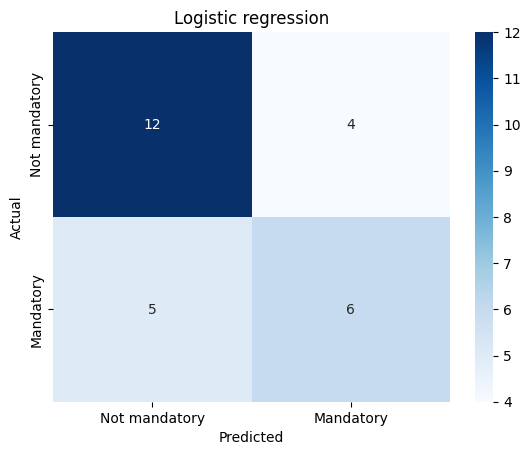

In [8]:
# Step 7: Confusion matrix for logistic regression, shown as a heatmap
# Rows = what is actually true, columns = what the model predicted.
# Top-left = correct "not mandatory" (TN), bottom-right = correct "mandatory" (TP),
# top-right = false alarms (FP), bottom-left = missed mandatory students (FN).
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not mandatory", "Mandatory"],
            yticklabels=["Not mandatory", "Mandatory"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic regression")
plt.show()

## Step 8: k-NN

For each test student, k-NN finds the **k most similar training students** (closest in feature space) and takes their **majority label**. We use **k = 5**, as in the slides. No scaling is needed because all features are 0/1.

**Result:** accuracy **0.78** (21 of 27). For the mandatory class: precision **1.00**, recall **0.45**.

- When k-NN says "mandatory" it is always right (5 of 5), but it finds only 5 of the 11 truly mandatory students. It is a *cautious* model.

| | Logistic regression | k-NN (k=5) |
|---|---|---|
| Accuracy | 0.67 | 0.78 |
| Precision (mandatory) | 0.60 | 1.00 |
| Recall (mandatory) | 0.55 | 0.45 |
| F1 (mandatory) | 0.57 | 0.62 |

k-NN scores higher on accuracy and F1, but that is 3 more students out of 27 on a single split. It is not strong evidence.

In [ ]:
# Step 8: k-NN with k=5
# Each test student gets the majority label of their 5 most similar training students.
# The result is saved in y_pred_knn, so the logistic regression result is kept.
# classification_report -> precision, recall and F1 for each class.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)
print("k-NN accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

## Step 9: Choosing k

**k** is a *hyperparameter*: we set it ourselves, the model does not learn it. A small k can **overfit** (it follows single odd points), a large k can **underfit** (it ignores the pattern). We compare accuracy on the training students with accuracy on the test students. Odd k values avoid tied votes.

**Result:** the accuracy barely changes (train 0.79-0.81, test 0.78 for every k).

- **Few different students:** with only four 0/1 columns there are at most 16 possible combinations. Many students have identical answers, so their nearest neighbours are copies of them, and k hardly matters.
- **Training accuracy at k=1 is only 0.81, not close to 1.00.** Some students have identical answers but different labels, and no model can separate them. About 80% is close to the ceiling for these four columns.
- **Train and test are close**, so there is no sign of overfitting or underfitting.
- **The exact numbers at the extremes (k = 1 and k = 21) can differ a little between computers and library versions.** Many students are identical, so the tie among equally close neighbours is broken arbitrarily. The pattern (about 0.7-0.8 accuracy, never near 1.00 on training data) stays the same.

There is nothing to tune, so we keep k = 5.

In [ ]:
# Step 9: Try different values of k
# Compare accuracy on the training students with accuracy on the test students.
# A big gap would mean overfitting. Odd k values avoid tied votes.
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    print(k, "train:", round(knn.score(X_train, y_train), 2),
             "test:", round(knn.score(X_test, y_test), 2))

## Conclusion

**Question:** Can a student's other reasons for taking the course predict whether they ticked "This was mandatory for me"?

**Answer:** Only a little. The motives carry some information, but not enough for a useful predictor.

| | Baseline | Logistic regression | k-NN (k=5) |
|---|---|---|---|
| Accuracy | 0.59 | 0.67 | 0.78 |
| Precision (mandatory) | - | 0.60 | 1.00 |
| Recall (mandatory) | - | 0.55 | 0.45 |
| F1 (mandatory) | - | 0.57 | 0.62 |

- Both models beat the baseline, but only by a few students out of 27, so we cannot say the difference is real.
- **Logistic regression** finds slightly more of the mandatory students (recall 0.55) but calls some students mandatory by mistake (precision 0.60).
- **k-NN** is cautious. Whenever it says "mandatory" it is right (precision 1.00), but it misses more than half of the truly mandatory students (recall 0.45).
- Which model is "better" depends on which mistake is worse: missing a mandatory student (choose recall) or flagging a student wrongly (choose precision).
- The value of k hardly mattered.

**Why the result is limited**

- **Small data:** only 133 students, and just 27 in the test set. One student is worth about 3.7 percentage points, so the scores depend a lot on which students end up in the test set. A more reliable estimate would repeat the test on many different splits (cross-validation).
- **Only four 0/1 features:** there are at most 16 different combinations of answers. Some students have identical answers but different labels, so no model can separate them. This sets a ceiling on the accuracy.
- **The form itself:** everyone had to tick at least one reason. A student who ticked no other motive must have ticked "mandatory", so part of the pattern comes from how the question was asked, not from the students.

**What we learned:** students who had to take the course tend to name fewer other reasons. That is a real pattern in the answers, but a weak basis for predicting anything about a new student.